In [1]:
import numpy as np
from scipy.sparse.linalg import svds
import fastplotlib as fpl
from matplotlib import pyplot as plt
import seaborn as sns
from tqdm import tqdm
from itertools import product
from typing import *
from time import time
import tifffile
import h5py

Unable to find extension: VK_EXT_swapchain_colorspace


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Available devices:
✅ (default) | AMD RADV POLARIS10 (ACO) | DiscreteGPU | Vulkan | Mesa 20.3.5 (ACO)
❗ | llvmpipe (LLVM 11.0.1, 256 bits) | CPU | Vulkan | Mesa 20.3.5 (LLVM 11.0.1)
✅ | NVIDIA GeForce RTX 3080 | DiscreteGPU | Vulkan | 530.30.02
❗ | Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1) | Unknown | OpenGL | 


In [2]:
f = h5py.File("/home/kushal/lab/datasets/gcamp8f/jGCaMP8f_ANM471993_cell02.nwb")

In [3]:
f["acquisition"].keys()

<KeysViewHDF5 ['Registered movie 0', 'Registered movie 1', 'Registered movie 2', 'Registered movie 3', 'Registered movie 4', 'Registered movie 5', 'loose seal recording for movie 0', 'loose seal recording for movie 1', 'loose seal recording for movie 2', 'loose seal recording for movie 3', 'loose seal recording for movie 4', 'loose seal recording for movie 5']>

In [4]:
movie = f["acquisition"]["Registered movie 1"]["data"]#[:10_000]

In [5]:
std = np.mean(movie, axis=0)

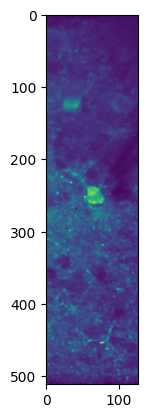

In [6]:
plt.imshow(std)

In [7]:
iw = fpl.ImageWidget(std, cmap="gnuplot2")
iw.show()

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:34: UserWarning: converting float64 array to float32
  warn(f"converting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [10]:
neurons = list()

for sel in iw.gridplot[0, 0].selectors:
    vs = sel.get_vertices()
    x1, x2 = int(vs[:, 0].min()), int(vs[:, 0].max())
    y1, y2 = int(vs[:, 1].min()), int(vs[:, 1].max())
    neurons.append(movie[:, y1:y2, x1:x2])

In [11]:
iw_crop = fpl.ImageWidget(neurons, cmap="gnuplot2")
iw_crop.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [13]:
centered = [c - c.mean() for c in neurons]

In [18]:
%matplotlib inline

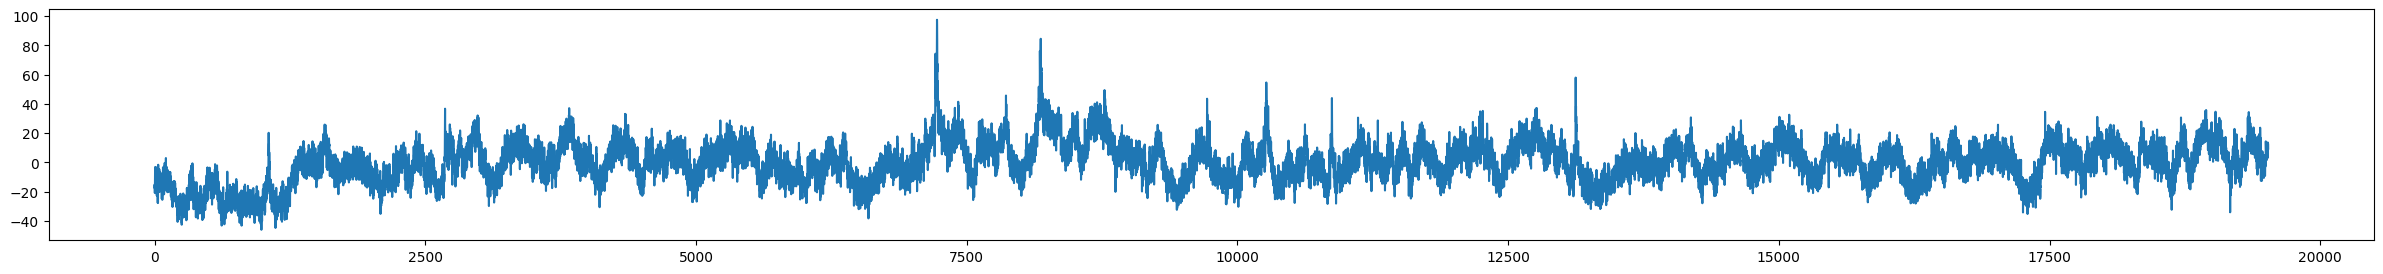

In [25]:
fig = plt.figure(figsize=(30, 3))
plt.plot(centered[2].mean(axis=(1, 2)))
plt.show()

In [78]:
plt.close()

In [26]:
class TdSVD:
    def __init__(
        self,
        movie: np.ndarray,
        n_time_steps: int,
        delay: int,
    ):
        self.n_time_steps = n_time_steps
        self.movie_mean = movie.mean(axis=0)
        
        frame = movie[0]
        self.xdim, self.ydim = frame.shape[0], frame.shape[1]
        
        n_pixels = self.xdim * self.ydim
        n_timepoints = movie.shape[0]
        
        self.A = np.zeros(shape=(n_pixels * n_time_steps, n_timepoints - n_time_steps), dtype=np.float32)
        A_ixs = np.zeros(n_pixels * n_time_steps)
        
        for pixel_ix, (x, y) in tqdm(enumerate(product(range(self.xdim), range(self.ydim))), total=n_pixels):
            for step in range(n_time_steps):
                self.A[(n_time_steps * pixel_ix) + step] = np.roll(movie[:, x, y], shift=-delay * step)[:-n_time_steps]

        self.k, self.U, self.S, self.V = None, None, None, None
    
    def fit(self, k=6, **kwargs):
        self.k = k
        t0 = time()
        self.U, self.S, self.V = svds(self.A, k=k, **kwargs)
        self.U = self.U[:, ::-1]
        self.S = self.S[::-1]
        self.V = self.V[::-1, :]
        t1 = time()
        print(f"svd took: {t1 - t0:.02f} sec")

    def get_spatial(self):
        """
        Returns
        -------
        np.ndarray
            [n_time_steps, k, ydim, xdim]
        """
        return np.array([self.U.reshape((self.xdim, self.ydim, self.n_time_steps, self.k))[..., i, :].transpose(2, 0, 1) for i in range(self.n_time_steps)])

In [27]:
td_svd = TdSVD(
    movie=centered[2],
    n_time_steps=15,
    delay=1,
)

100%|███████████████████████████████████████████████████████████████████████████████████████| 1840/1840 [00:01<00:00, 1435.00it/s]


In [28]:
td_svd.fit(k=10)

svd took: 7.92 sec


In [29]:
spatial = td_svd.get_spatial()

In [30]:
spatial.shape

(15, 10, 40, 46)

In [31]:
iw_steps = fpl.ImageWidget(
    data=[spatial[step] for step in range(td_svd.n_time_steps)],
    names=[f"step-{i}" for i in range(td_svd.n_time_steps)],
    grid_plot_kwargs={"size": (1500, 400)}
)
iw_steps.show()

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:34: UserWarning: converting float64 array to float32
  warn(f"converting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(css_height='400px', css_width='1500px'), IpywidgetToolBar(chi…

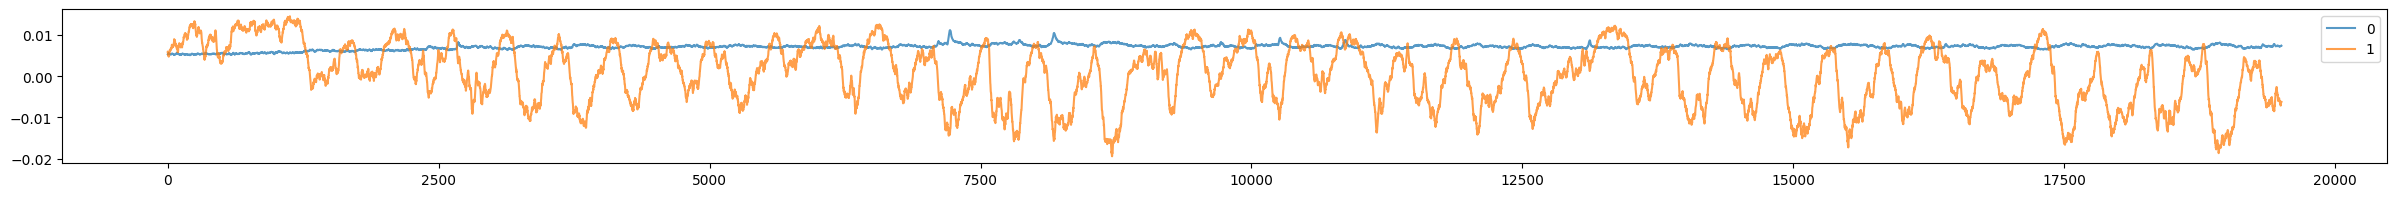

In [32]:
fig = plt.figure(figsize=(30, 2))

for i, vi in enumerate(td_svd.V):
    # fig = plt.figure(figsize=(50, 2))
    plt.plot(vi, label=str(i), alpha=0.75)
    # plt.show()
    if i == 1:
        break
    # plt.show()
plt.legend()
plt.show()

In [63]:
plt.close()

In [33]:
iw_steps = fpl.ImageWidget(
    data=[spatial[:, k_step] for k_step in range(td_svd.k)],
    names=[f"step-{i}" for i in range(td_svd.k)],
    grid_plot_kwargs={"size": (1500, 400)}
)

plot_lines = fpl.Plot()
plot_lines.docks["right"].size = 70

# legend = fpl.Legend(plot_lines.docks["right"])
# for i, (vi, c) in enumerate(zip(td_svd.V, ["red", "orange", "yellow", "green", "blue", "purple"])):
#     l = plot_lines.add_line(vi, colors=c, name=f"{i}")
    # legend.add_graphic(l, label=f"{i}---")

# plot_lines.show()

iw_steps.show()
# HBox([iw_steps.widget, plot_lines.widget])

RFBOutputContext()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(css_height='400px', css_width='1500px'), IpywidgetToolBar(chi…

In [36]:
u, s, v = svds(centered[2].reshape(centered[2].shape[0], centered[2].shape[1] * centered[2].shape[2]).T.astype(np.float32), k=10)

In [37]:
u = u[:, ::-1]
s = s[::-1]
v = v[::-1]

In [38]:
%matplotlib inline

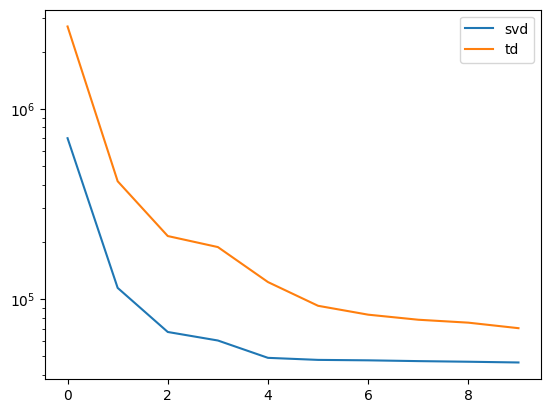

In [39]:
plt.plot(s[:], label="svd")
plt.plot(td_svd.S[:], label="td")
plt.yscale("log")
plt.legend()
plt.show()

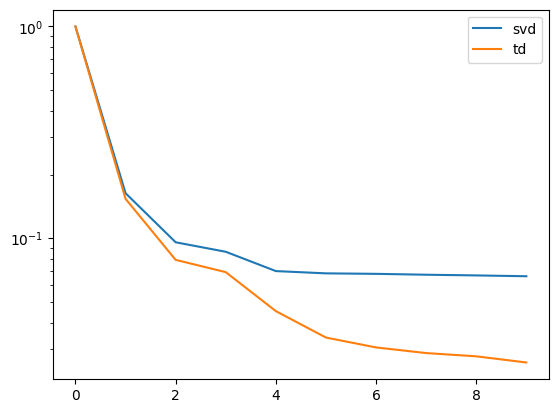

In [40]:
plt.plot(s[:] / s.max(), label="svd")
plt.plot(td_svd.S / td_svd.S.max(), label="td")
plt.yscale("log")
plt.legend()

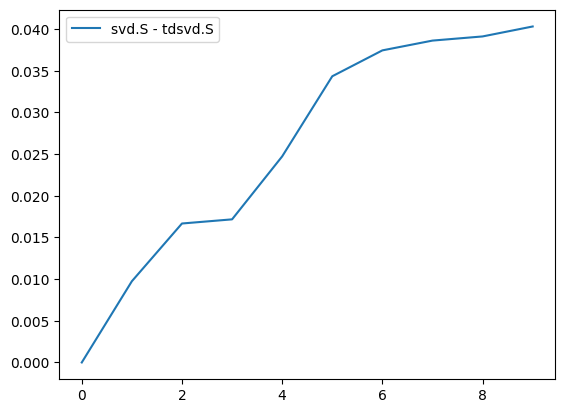

In [42]:
plt.plot((s[:] / s.max()) - (td_svd.S / td_svd.S.max()), label="svd.S - tdsvd.S")
# plt.yscale("log")
plt.legend()